In [3]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
os.chdir('/Users/oyieth/Documents/Python projects/credit_scoring_examples')
from src.distributions import group_data_dist,pie_distribution,target_barchart

# Applications set
## Target distribution

How many missing values are there? are there any columns
**Categorical values: for these:**
 1. distribution in the data set
 1. distribution of target ¿Which one has more?
### Categorical columns
 ~~~NAME_CONTRACT_TYPE   CODE_GENDER	FLAG_OWN_CAR	FLAG_OWN_REALTY	CNT_CHILDREN
  #NAME_TYPE_SUITE	NAME_INCO
  ME_TYPE	NAME_EDUCATION_TYPE	NAME_FAMILY_STATUS	NAME_HOUSING_TYPE
 #OCCUPATION_TYPE	 ORGANIZATION_TYPE
 #FLAG_MOBIL	FLAG_EMP_PHONE	FLAG_WORK_PHONE	FLAG_CONT_MOBILE	FLAG_PHONE	FLAG_EMAIL```
~~~
probably many of those won't be useful, choose intereseting ones
### numerical values
    1.  distribution
    1. correlation betwwen numeric columns

# Other sets
    1. In the previous application set is there any variable that wasn't in the application set?
    1. Are all other previous sets numerics, which non-numerical variables are there

# Intro

Structure:
In this document we can se some superficial insights from the datasets. Previously I developed a simple streamlit visualiser to see in which variables I could focus.

By dataset we will have the following structure:
* Presence of null values.
* Correlation in numerical values
* Distribution of categorical and numerical features.
* For the train set, how is this distribution linked with the target variable
* For other sets how could we use this info as input for a model.

# Application Info

We will focus on the train dataset.

In [25]:
application_train = pd.read_csv("data/application_train.csv")
application_test = pd.read_csv("data/application_test.csv")

We will validate the dataset size and the number of loans. 

In [4]:
application_train.shape

(307511, 122)

In [5]:
application_train.SK_ID_CURR.nunique()

307511

As expected, we have one ID Record per row.

## Target distribution 

How many loans had any difficulty with payment?

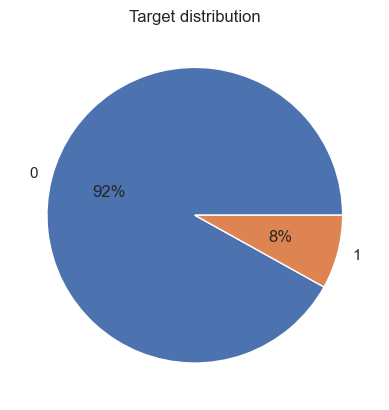

In [6]:
sns.set_theme()
#target_dist = 
g = pie_distribution(application_train, "TARGET")
g.set_title("Target distribution");

About 8% of the train set population has had difficulty with payments. We are working with unbalanced  data

## Missing values

First we will see which features have the most missing values. We find that these are mostly features related with where the client lives.

In [7]:
missing =(application_train.isna().sum()/application_train.shape[0]).sort_values(ascending = False)
missing.head(20)

COMMONAREA_MEDI             0.698723
COMMONAREA_AVG              0.698723
COMMONAREA_MODE             0.698723
NONLIVINGAPARTMENTS_MODE    0.694330
NONLIVINGAPARTMENTS_AVG     0.694330
NONLIVINGAPARTMENTS_MEDI    0.694330
FONDKAPREMONT_MODE          0.683862
LIVINGAPARTMENTS_MODE       0.683550
LIVINGAPARTMENTS_AVG        0.683550
LIVINGAPARTMENTS_MEDI       0.683550
FLOORSMIN_AVG               0.678486
FLOORSMIN_MODE              0.678486
FLOORSMIN_MEDI              0.678486
YEARS_BUILD_MEDI            0.664978
YEARS_BUILD_MODE            0.664978
YEARS_BUILD_AVG             0.664978
OWN_CAR_AGE                 0.659908
LANDAREA_MEDI               0.593767
LANDAREA_MODE               0.593767
LANDAREA_AVG                0.593767
dtype: float64

¿Which features have more than half their records as missing values?

In [8]:
len(missing[missing>0.5])/len(missing)

0.3360655737704918

Around one in three variables from the application set have more than half the records as missing values.

## Correlations in numerical variables

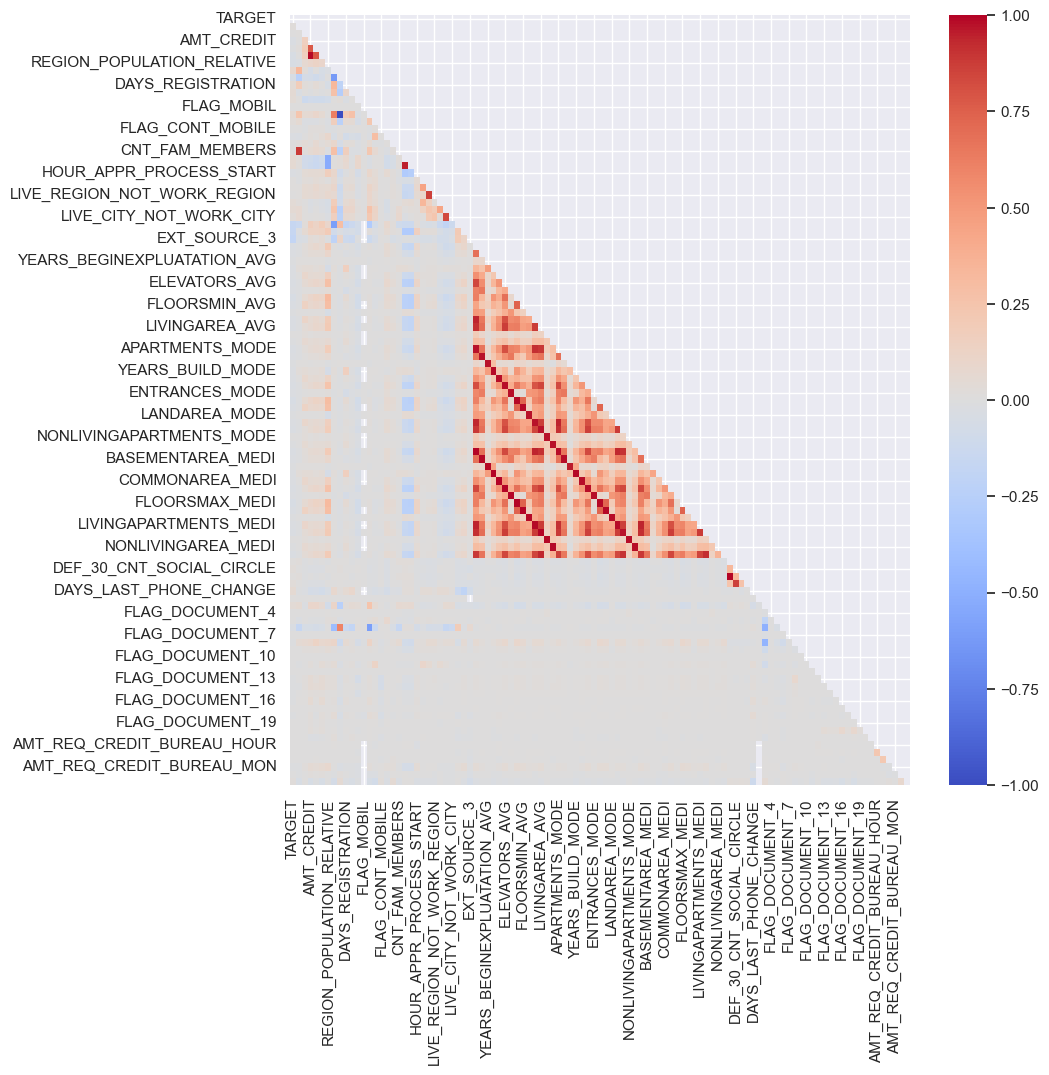

In [9]:
fig, ax = plt.subplots(1,1,)
fig.set_size_inches(10,10)
# creating mask 
do_not_consider = ["SK_ID_CURR",
           "SK_BUREAU_ID",
           "SK_ID_PREV"
               "SK_ID_BUREAU",
           ]
df = application_train
types = {col:str(df[col].dtype) for  col in df.columns}
columns =[item for item in types if types[item] != 'object' and item not in do_not_consider]
mask = np.triu(np.ones_like(df[columns].corr())) 
  
# plotting a triangle correlation heatmap 
fig, ax
dataplot = sns.heatmap(df[columns].corr().round(2), cmap="coolwarm", annot=False,mask=mask,ax=ax,vmax=1,vmin=-1)

* There's a ser of variables which seem to have correlation. These are variables regarding building where the client lives. 
* One can't appreciate yet a correlation between the target variable and these numerical variables.

## Categorical variables

As

### Gender

Here there are two simple questions. Are there more men of woman in these loan applications? Do any of these genders seem to have more difficulties with payments=

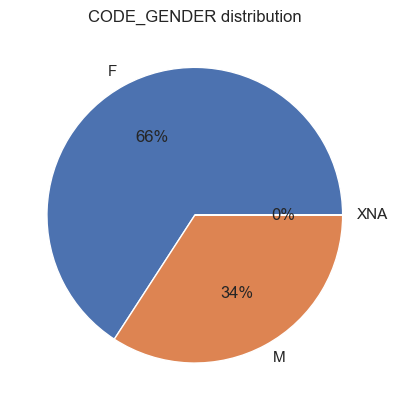

In [12]:

k = pie_distribution(application_train,"CODE_GENDER")

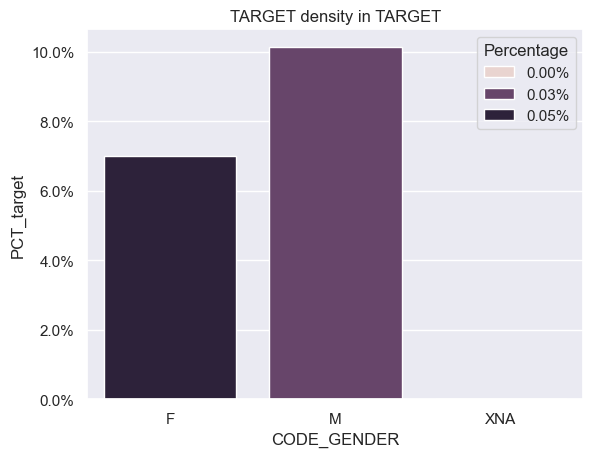

In [14]:

k = target_barchart(df = application_train,
                    chart_col = "CODE_GENDER",
                    target_col = "TARGET")

There seems to be more female applicants than male applicants. However, almost 10% of the male population seems to have had problems with their loan payments.

In [ ]:
### Owns car and flat

TypeError: pie_distribution() got an unexpected keyword argument 'ax'

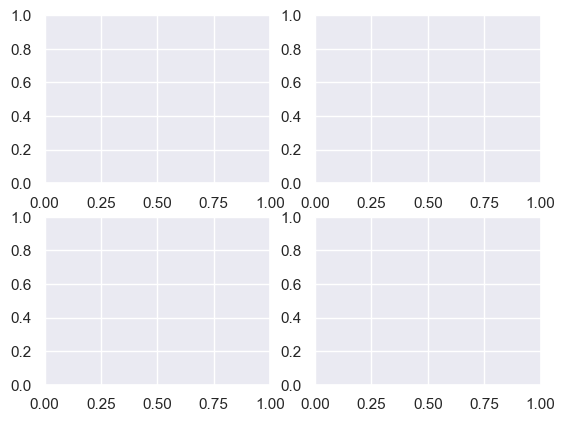

<Figure size 1000x800 with 0 Axes>

In [43]:
fig, ax = plt.subplots(2,2)
fig = plt.figure(figsize=(10, 8))


f = pie_distribution(application_train,"FLAG_OWN_CAR", ax = ax[0][0])

g = pie_distribution(application_train,"FLAG_OWN_REALTY", ax = ax[0][1])


l = target_barchart(df = application_train,
                    chart_col = "FLAG_OWN_CAR",
                    target_col = "TARGET",
                   ax = ax[1][0])

m = target_barchart(df = application_train,
                    chart_col = "FLAG_OWN_REALTY",
                    target_col = "TARGET",
                   ax = ax[1][1])



The applicants seem to be mainly people who own their homes but do not own a car. However, 

### Occupation type

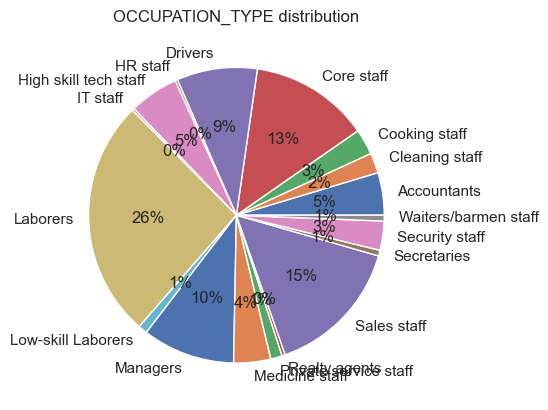

In [48]:
pie_distribution(application_train,"OCCUPATION_TYPE", );

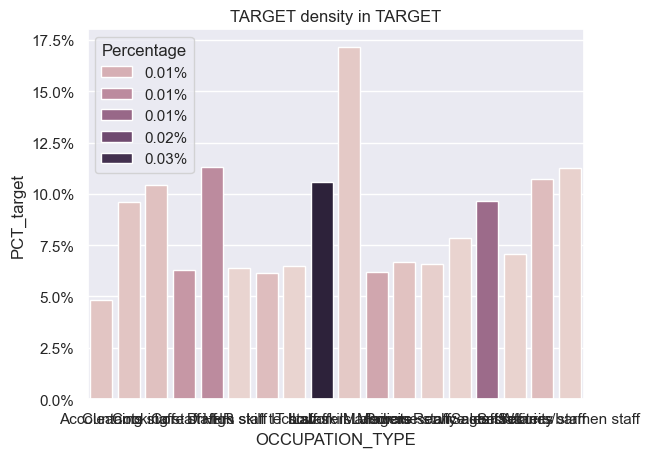

In [50]:
target_barchart(application_train,"OCCUPATION_TYPE", target_col='TARGET' );

## Numerical variables

### AMT_INCOME_TOTAL

In [54]:
application_train["AMT_INCOME_TOTAL"].describe()

count    3.075110e+05
mean     1.687979e+05
std      2.371231e+05
min      2.565000e+04
25%      1.125000e+05
50%      1.471500e+05
75%      2.025000e+05
max      1.170000e+08
Name: AMT_INCOME_TOTAL, dtype: float64

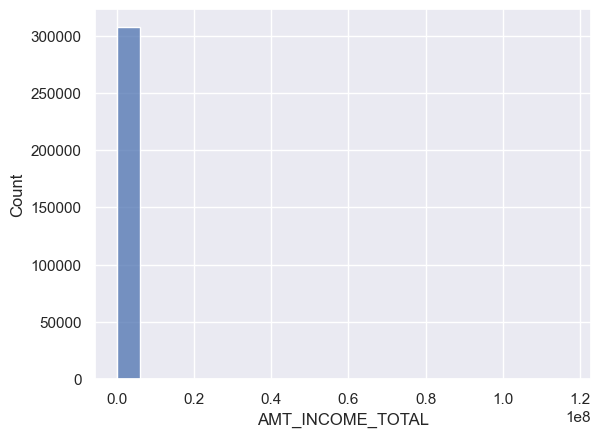

In [52]:
sns.histplot(data = application_train,
             x = "AMT_INCOME_TOTAL",
            bins = 20);

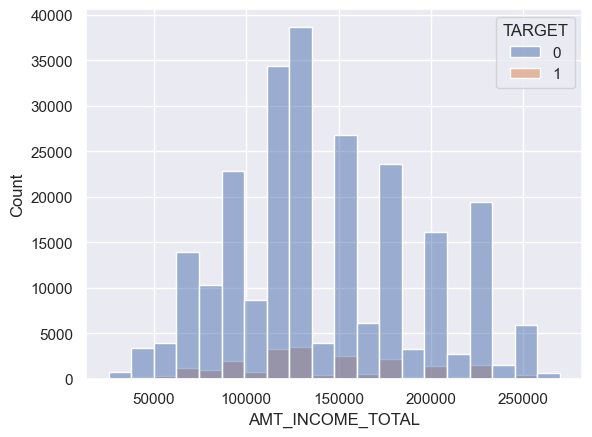

In [79]:
sns.histplot(data = application_train[application_train["AMT_INCOME_TOTAL"]<application_train["AMT_INCOME_TOTAL"].quantile(0.9)],
             x = "AMT_INCOME_TOTAL",
             bins = 20,
            hue = "TARGET");

/var/folders/bb/jt4g1cyj7fv862k5cn392htr0000gn/T/ipykernel_3126/1236772392.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  income_brackets["BRACKET"] = income_brackets["AMT_INCOME_TOTAL"].apply(lambda x: 250000 if x>250000 else x).apply(lambda x: int(x/50000)*50000)


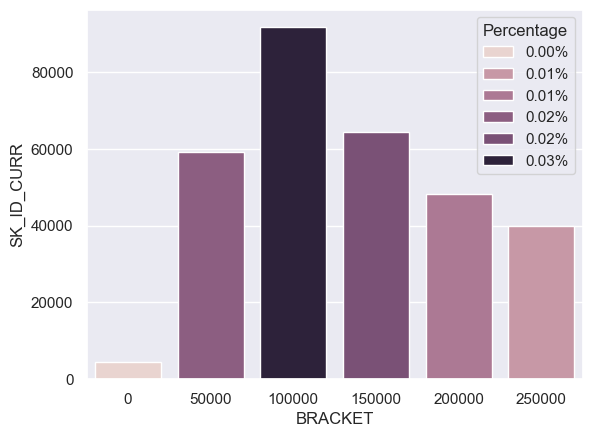

In [76]:
income_brackets = application_train[["AMT_INCOME_TOTAL", "TARGET","SK_ID_CURR"]]
income_brackets["BRACKET"] = income_brackets["AMT_INCOME_TOTAL"].apply(lambda x: 250000 if x>250000 else x).apply(lambda x: int(x/50000)*50000)
income_brackets_group = income_brackets.groupby(by = "BRACKET").agg({"SK_ID_CURR":"count", "TARGET": "sum"})
income_brackets_group["TARGET_PCT"] = income_brackets_group["TARGET"] / income_brackets_group["SK_ID_CURR"].sum()
g = sns.barplot(income_brackets_group,
            x= "BRACKET",
            y = "SK_ID_CURR",
             hue = "TARGET_PCT")
handles, labels = g.get_legend_handles_labels()
new_labels = [f"{float(label):.2f}%" for label in labels]
g.legend(handles, new_labels, title="Percentage")


### DAYS_BIRTH


<Axes: xlabel='DAYS_BIRTH', ylabel='Count'>

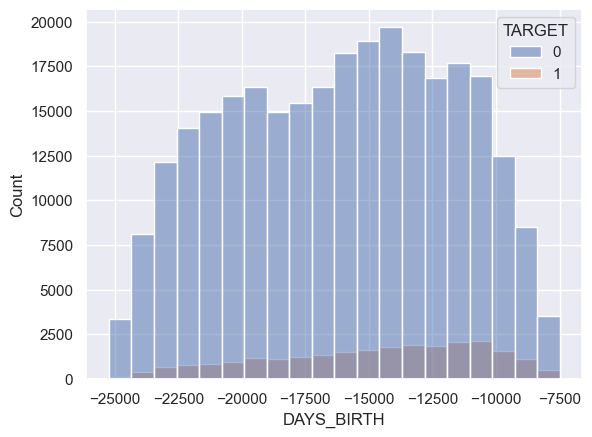

In [81]:
sns.histplot(data = application_train,
             x = "DAYS_BIRTH",
             bins = 20,
            hue = "TARGET")

### DAY EMPLOYED

<Axes: xlabel='DAYS_EMPLOYED', ylabel='Count'>

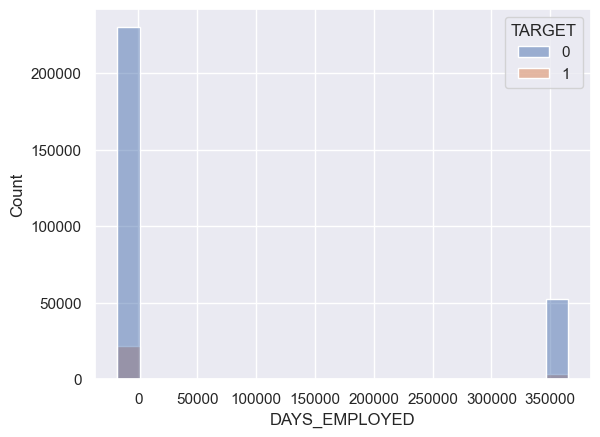

In [82]:
sns.histplot(data = application_train,
             x = "DAYS_EMPLOYED",
             bins = 20,
            hue = "TARGET")

Here there seems to be a high concentration of clients which seem to have days of employment _after_ the day of the application. Seeing the distribution with these clientes, we have an expected distribution.

<Axes: xlabel='DAYS_EMPLOYED', ylabel='Count'>

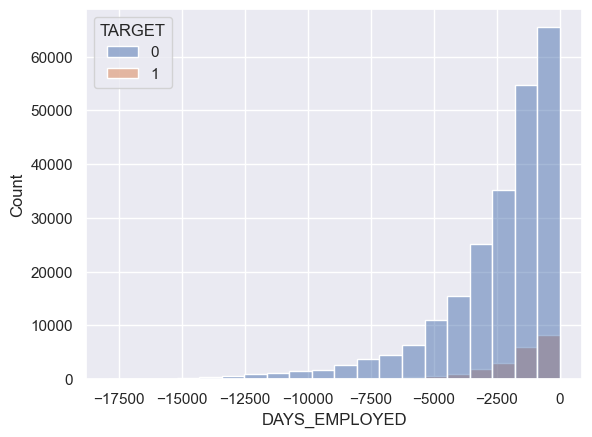

In [83]:
sns.histplot(data = application_train[application_train["DAYS_EMPLOYED"]<350000],
             x = "DAYS_EMPLOYED",
             bins = 20,
            hue = "TARGET")

There's the question, what kind of income have this applicants with these values. They seem to be mostly penioned cleaning staff.

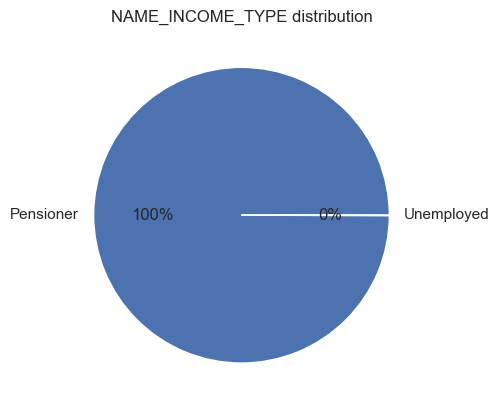

In [99]:
pie_distribution(application_train[application_train["DAYS_EMPLOYED"]>0],"NAME_INCOME_TYPE", );

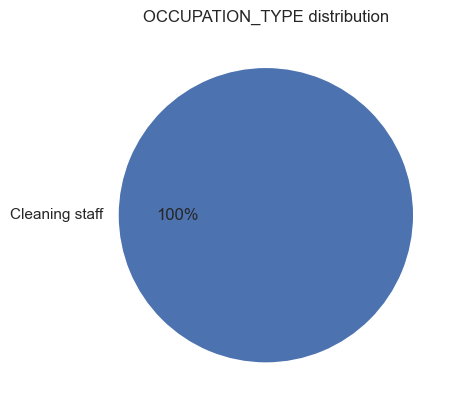

In [98]:
pie_distribution(application_train[application_train["DAYS_EMPLOYED"]>0],"OCCUPATION_TYPE", );

### OWN_CAR_AGE

<Axes: xlabel='OWN_CAR_AGE', ylabel='Count'>

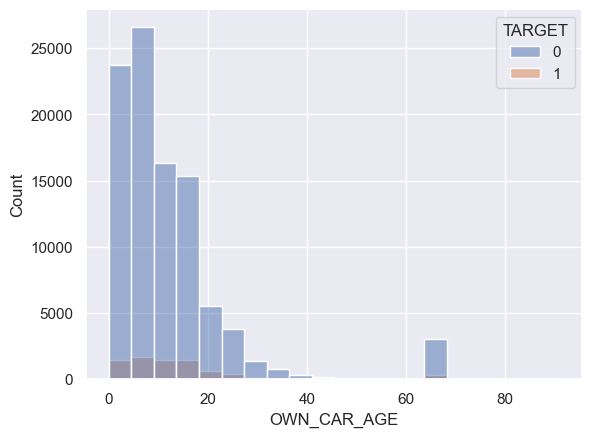

In [84]:

sns.histplot(data = application_train,
             x = "OWN_CAR_AGE",
             bins = 20,
            hue = "TARGET")

In [ ]:
Again, there seems to be a high concentration of cars over 50 years. P

<Axes: xlabel='OWN_CAR_AGE', ylabel='Count'>

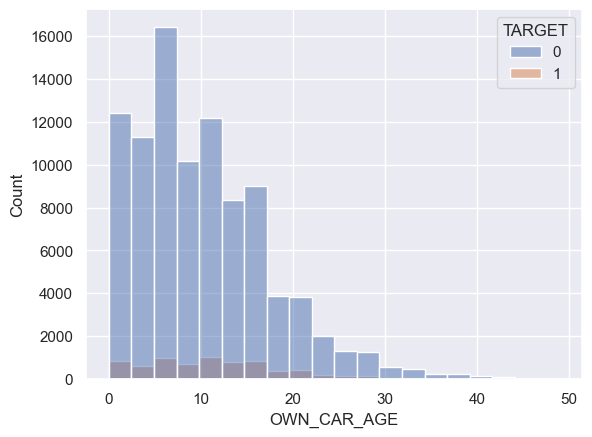

In [102]:

sns.histplot(data = application_train[application_train["OWN_CAR_AGE"]<50],
             x = "OWN_CAR_AGE",
             bins = 20,
            hue = "TARGET")

In [106]:
### AMT_REQ_CREDIT_BUREAU

<Axes: xlabel='AMT_REQ_CREDIT_BUREAU_YEAR', ylabel='Count'>

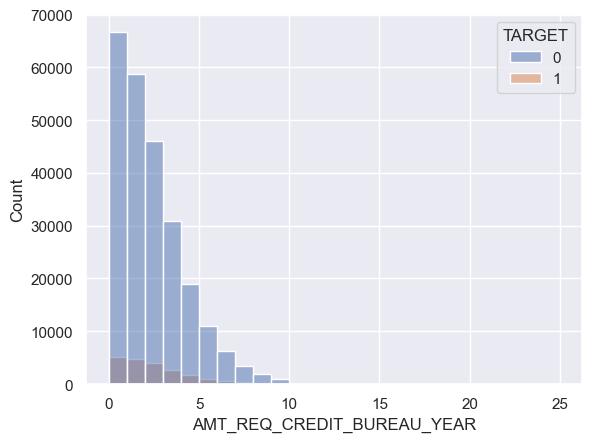

In [93]:

sns.histplot(data = application_train,
             x = "AMT_REQ_CREDIT_BUREAU_YEAR",
             bins = 25,
            hue = "TARGET")

In [117]:
bureau.groupby(by = "SK_ID_CURR").SK_ID_BUREAU.count().describe()

count    305811.000000
mean          5.612709
std           4.430354
min           1.000000
25%           2.000000
50%           4.000000
75%           8.000000
max         116.000000
Name: SK_ID_BUREAU, dtype: float64

# Other sets
For the rest of sets we will focus mainly in the creation of possible features for a model. 